# GVH–CHH — Jupiter / JPL Horizons / robustesse 3D (FAST)

**Notebook** : `GVH_CHH_Jupiter_Horizons_3D_Independent_Orbit_And_Null_Systematics_Gate_FAST`  
**Date** : 2026-11-20 ; **prédécesseur SHA-256** : `ac70c063625d87cc94211dabb7a2a61908f2ea050faccd1a8093ce84782f4c0e`  
**Protocole** : `GVH_CHH_PROTOCOL_FROZEN_v1.0` (composition CHH sans EOM intrinsèque).  
**Statut scientifique** : branche `INVERSE-INFERENCE` + `KNOWN-PHYSICS` + `NUMERICAL-TEST`; `GVH_USED=False` ; `EOM_GVH=False` ; `ALMA_USED=False`.

**Séparation des preuves** :

1. `SYNTHETIC_3D_EXECUTED` : perturbations newtoniennes 3D calculées ici, avec quadrupôle J2 orienté et Callisto connue. Dans les contrôles masqués, la vérité injectée n'est consultée que pour le verdict.
2. `JPL_HORIZONS_REAL_EPHEMERIS` : source publique **JPL Horizons** (Io 501, Ganymède 503, Callisto 504), centre `500@599` (Jupiter), référence `ICRF`, unités `KM-S`, corrections vectorielles géométriques `NONE`, 2026-09-01 → 2026-09-25 à 6 h. Sur Colab, le notebook essaie de télécharger réellement ces séries. Si l'accès Internet est absent, le statut est `PENDING` : **aucun chiffre ne sera attribué à des données réelles**.
3. `REAL_BASELINE_DIAGNOSTIC_ONLY` : même après téléchargement, comparaison à une référence éphéméride calculée par JPL (pas à une mesure astrométrique indépendante), dans un modèle simplifié **incomplet** ; aucune revendication de découverte ni hypothèse gravitationnelle nouvelle.

**Sources** : [JPL Horizons API](https://ssd-api.jpl.nasa.gov/doc/horizons.html) ; [NASA Jupiter Fact Sheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html) (J2 et axe, approximation) ; [JPL Horizons manual](https://ssd.jpl.nasa.gov/horizons/manual.html).

**Contraintes préfixées** : modèles H0/H1, paramétrage, bruit synthétique σ = 8 km par coordonnée, entraînement `t <= 15` jours, validation réservée `t > 15` jours, décision exploratoire BIC (non calibrée comme p-value), gardes contre effet J2 omis et lune connue Callisto omise.

## Niveau 1 — Modèle CHH et inconnues

Le cube Jupiter contient des sous-cubes observés (Io, Ganymède) et un perturbeur **connu** (Callisto). On teste si des résidus exigent un sous-cube supplémentaire. 

**H0** : aucun perturbateur caché ; **H1** : un perturbateur candidat (rayon, phase, paramètre gravitationnel $GM$), hypothèse orbitale proche du plan équatorial **fixée**. Le modèle n'explore ni 2 perturbateurs ni toutes les inclinaisons : une sélection H1 ne représente pas la preuve d'une lune réelle. 

Les dérivées sont des outils numériques/auxiliaires (`AUX-DERIVATIVE`), et l'intégration utilise exclusivement des équations newtoniennes connues. La sélection BIC sous H1 est une **heuristique** : les paramètres rayon et phase sont non identifiables si la masse du perturbateur est nulle. Aucun seuil de significativité calibré n'est revendiqué.

## Niveau 2 — Physique connue et cadre tridimensionnel

Pour un vecteur unitaire de pôle $\mathbf p$, $s=\mathbf p\cdot\mathbf r/r$, le potentiel spécifique simplifié autour de Jupiter est

\[
U=-\frac{\mu_J}{r}\left[1-J_2\left(\frac{R_J}{r}\right)^2\frac{3s^2-1}{2}\right].
\]

L'accélération $-\nabla U$ donne

\[
\mathbf a=-\frac{\mu_J\mathbf r}{r^3}
+\frac{3\mu_JJ_2R_J^2}{2r^5}\left[(5s^2-1)\mathbf r-2(\mathbf p\cdot\mathbf r)\mathbf p\right].
\]

On ajoute les termes Newtoniens directs/indirects de perturbation des autres satellites connus. **Ce n'est pas un intégrateur gravitationnel complet** : les marées, Soleil, J4/J6, autres lunes, estimation d'état et rotations temporelles ne sont pas modélisés. Le pôle ICRF est approximé par RA=268.056595−0.006499T°, Dec=64.495303+0.002413T° (T en siècles juliens depuis J2000) ; nutations et variations rapides sont ignorées. La fenêtre de 24 jours est courte. Les orbites synthétiques sont proches du plan équatorial mais non exactement coplanaires.

Les conditions initiales synthétiques sont **prescrites**, pas retrouvées par CHH ; la phase et le rayon du candidat sont ajustés uniquement sur entraînement. Aucun réel Io/Ganymède n'est divulgué au fit si les séries JPL ne sont pas récupérées.

In [1]:
import numpy as np, json, hashlib, math
from numba import njit
from scipy.optimize import least_squares

GM_J=126686534.0
R_J=71492.0
J2=0.014736
GM_IO=5959.916
GM_GAN=9887.834
GM_CALL=7179.29
SEC_D=86400.0
FAC=SEC_D**2
DT=0.025; STRIDE=10; NSTEPS=960
TIMES=np.arange(NSTEPS//STRIDE+1)*DT*STRIDE
TRAIN=TIMES<=15+1e-9; HOLD=~TRAIN
NOISE=8.0
SEED=20261120
ra=np.deg2rad(268.056595-0.006499*(26.75/100))
dec=np.deg2rad(64.495303+0.002413*(26.75/100))
POLE=np.array([np.cos(dec)*np.cos(ra),np.cos(dec)*np.sin(ra),np.sin(dec)])
e1=np.cross(np.array([0.,0.,1.]),POLE);e1=e1/np.linalg.norm(e1);e2=np.cross(POLE,e1)

def orbit_init(a,phi,inc):
 er=np.cos(phi)*e1+np.sin(phi)*(np.cos(inc)*e2+np.sin(inc)*POLE)
 et=-np.sin(phi)*e1+np.cos(phi)*(np.cos(inc)*e2+np.sin(inc)*POLE)
 return a*er,np.sqrt(GM_J/a)*et
R0=[];V0=[]
for a,phi,inc in [(421800.,0.15,0.006),(1070400.,2.1,0.017),(1882700.,4.1,0.011)]:
 r,v=orbit_init(a,phi,inc);R0.append(r);V0.append(v)
R0=np.array(R0);V0=np.array(V0);MASS=np.array([GM_IO,GM_GAN,GM_CALL])

@njit
def accel3(r,gm,j2,pole):
 n=r.shape[0];out=np.zeros((n,3))
 for i in range(n):
  x=r[i,0];y=r[i,1];z=r[i,2]
  q=x*x+y*y+z*z;norm=np.sqrt(q);s=(x*pole[0]+y*pole[1]+z*pole[2])/norm
  pre=-GM_J*FAC/(q*norm)
  jpre=1.5*GM_J*FAC*j2*R_J*R_J/(q*q*norm)
  for d in range(3):
   out[i,d]=pre*r[i,d]+jpre*((5*s*s-1)*r[i,d]-2*(s*norm)*pole[d])
  for j in range(n):
   if i==j:continue
   dx=r[j,0]-x;dy=r[j,1]-y;dz=r[j,2]-z
   dr2=dx*dx+dy*dy+dz*dz;dr3=dr2*np.sqrt(dr2)
   j2norm=r[j,0]**2+r[j,1]**2+r[j,2]**2;jnorm3=j2norm*np.sqrt(j2norm)
   out[i,0]+=(gm[j]*FAC)*(dx/dr3-r[j,0]/jnorm3)
   out[i,1]+=(gm[j]*FAC)*(dy/dr3-r[j,1]/jnorm3)
   out[i,2]+=(gm[j]*FAC)*(dz/dr3-r[j,2]/jnorm3)
 return out

@njit
def integrate3(r_in,v_in,gm,j2,pole):
 r=r_in.copy();v=v_in*SEC_D
 obs=np.zeros((NSTEPS//STRIDE+1,2,3));obs[0]=r[:2]
 for step in range(1,NSTEPS+1):
  acc=accel3(r,gm,j2,pole)
  v+=0.5*DT*acc
  r+=DT*v
  acc=accel3(r,gm,j2,pole)
  v+=0.5*DT*acc
  if step%STRIDE==0:
   obs[step//STRIDE]=r[:2]
 return obs

def simulate(j2=J2,hidden=None,known_callisto=True,pole=POLE,real_r=None,real_v=None):
 r=R0.copy() if real_r is None else real_r.copy()
 v=V0.copy() if real_v is None else real_v.copy()
 gm=MASS.copy()
 if not known_callisto:
  r=r[:2];v=v[:2];gm=gm[:2]
 if hidden is not None:
  a,phi,mu=hidden
  rr,vv=orbit_init(a,phi,0.012)
  r=np.vstack([r,rr]);v=np.vstack([v,vv]);gm=np.append(gm,mu)
 return integrate3(r,v,gm,j2,pole)

B=np.zeros((len(TIMES)*6,12))
for k in range(6):
 for i,t in enumerate(TIMES):
  B[6*i+k,2*k]=1
  B[6*i+k,2*k+1]=t
SEL=np.repeat(TRAIN,6);HOLDS=np.repeat(HOLD,6)
Q,_=np.linalg.qr(B[SEL],mode='reduced')

def residual(obs,pred,training=True):
 d=(obs-pred).ravel()
 if training:
  v=d[SEL]
  return v-Q@(Q.T@v)
 c=np.linalg.lstsq(B[SEL],d[SEL],rcond=None)[0]
 return d[HOLDS]-B[HOLDS]@c

def holdout_rmse(obs,pred):
 return float(np.sqrt(np.mean(residual(obs,pred,False)**2)))

def bic(res,k):
 n=len(res);ss=float(np.dot(res,res));return float(n*np.log(max(ss,1e-18)/n)+k*np.log(n))

coarse_a=np.array([525000.,625000.,700000.,800000.,900000.])
coarse_phi=np.linspace(0,2*np.pi,16,endpoint=False)

def fit_hidden(obs,j2,known_callisto=True,topn=5):
 base=simulate(j2=j2,known_callisto=known_callisto)
 y=residual(obs,base)
 opts=[]
 for a in coarse_a:
  for phase in coarse_phi:
   diff=simulate(j2=j2,hidden=(a,phase,3000.),known_callisto=known_callisto)-base
   u=residual(diff,np.zeros_like(diff))/3 # derivative per 1000 GM
   denom=float(np.dot(u,u))
   if denom<1e-15:continue
   mu1000=np.clip(np.dot(u,y)/denom,0.,12.)
   ss=float(np.dot(y-mu1000*u,y-mu1000*u))
   opts.append((ss,a,phase,mu1000))
 opts.sort(key=lambda x:x[0])
 def fun(p):
  pred=simulate(j2=j2,hidden=(p[0]*1e5,p[1],p[2]*1000.),known_callisto=known_callisto)
  return residual(obs,pred)
 results=[]
 for ss,a,phase,mu1000 in opts[:topn]:
  try:
   fit=least_squares(fun,[a/1e5,phase,np.clip(mu1000,0.,11.999)],bounds=([4.7,-1e-8,0.],[10.1,2*np.pi+1e-8,12.]),max_nfev=55,ftol=1e-8,xtol=1e-8,gtol=1e-8)
   results.append(fit)
  except Exception as e:
   pass
 if not results:raise RuntimeError('No hidden-moon fitting result')
 f=min(results,key=lambda x:float(x.fun@x.fun))
 pred=simulate(j2=j2,hidden=(float(f.x[0])*1e5,float(f.x[1]),float(f.x[2])*1000),known_callisto=known_callisto)
 return {'fit':f,'null_pred':base,'candidate_pred':pred,'bic0':bic(residual(obs,base),12),'bic1':bic(f.fun,15),'selected_n':int(bic(f.fun,15)<bic(residual(obs,base),12)),'holdout0':holdout_rmse(obs,base),'holdout1':holdout_rmse(obs,pred),'r_km':float(f.x[0]*1e5),'phase_rad':float(f.x[1]),'mu_km3s2':float(f.x[2]*1000)}

In [2]:
from pathlib import Path
import os, hashlib, json, csv, time
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import pandas as pd

NAME='GVH_CHH_Jupiter_Horizons_3D_Independent_Orbit_And_Null_Systematics_Gate_FAST'
OUT=Path('/content') if Path('/content').exists() else Path('/mnt/data')
OUT.mkdir(parents=True,exist_ok=True)
CHECKS=[]
def CK(label,passed,detail=''):
    z={'check':label,'pass':bool(passed),'detail':str(detail)}
    CHECKS.append(z)
    if not z['pass']:raise AssertionError(str(z))

def u3_j2_potential(r):
    r=np.asarray(r,float);rr=np.linalg.norm(r);s=np.dot(r,POLE)/rr
    return -GM_J/rr*(1-J2*(R_J/rr)**2*.5*(3*s*s-1))

def u3_j2_acc(r):
    r=np.asarray(r,float);rr=np.linalg.norm(r);s=np.dot(r,POLE)/rr
    return -GM_J*r/rr**3 + (1.5*GM_J*J2*R_J**2/rr**5)*((5*s*s-1)*r-2*np.dot(POLE,r)*POLE)

maxerr=0.
for xyz in [[421800.,-12000.,9000.],[-270000.,580000.,-340000.],[0.,1020000.,240000.]]:
    r=np.asarray(xyz,float);h=1.0
    gn=-np.array([(u3_j2_potential(r+h*np.eye(3)[d])-u3_j2_potential(r-h*np.eye(3)[d]))/(2*h) for d in range(3)])
    ga=u3_j2_acc(r)
    maxerr=max(maxerr,np.linalg.norm(gn-ga)/np.linalg.norm(ga))
CK('J2 potential analytic gradient matches finite differences',maxerr<1e-8,f'max relative error={maxerr:.3e}')
rot0=np.array([[0.,-1.,0.],[1.,0.,0.],[0.,0.,1.]])
x=np.array([680000.,240000.,-12000.]);p2=rot0@POLE;xr=rot0@x
s=np.dot(POLE,x)/np.linalg.norm(x); a=u3_j2_acc(x)
mu=GM_J; rr=np.linalg.norm(xr); sr=np.dot(p2,xr)/rr
ar=-mu*xr/rr**3+(1.5*mu*J2*R_J**2/rr**5)*((5*sr*sr-1)*xr-2*np.dot(p2,xr)*p2)
CK('3D rotational covariance of J2 acceleration',np.linalg.norm(rot0@a-ar)/np.linalg.norm(a)<1e-13)
CK('pole is unit length',abs(np.linalg.norm(POLE)-1)<1e-13)
CK('J2 reference positive',0<J2<0.03)
CK('3D time steps',len(TIMES)==97 and np.allclose(np.diff(TIMES),.25))
CK('training first 15 days only',int(TRAIN.sum())==61 and int(HOLD.sum())==36)
CK('train and holdout disjoint',not bool(np.any(TRAIN&HOLD)))
CK('3D known moon initial states are noncoplanar',float(np.abs(np.linalg.det(R0)))>1e8)
CK('finite known initial conditions',np.isfinite(R0).all() and np.isfinite(V0).all())
CK('Jupiter central units',GM_J>1e8 and 70000<R_J<72000)
print('3D PHYSICS VERIFICATION:',len(CHECKS),'checks passed; relative potential-gradient error',maxerr)

3D PHYSICS VERIFICATION: 10 checks passed; relative potential-gradient error 7.223467611389947e-11


## Niveau 3a — Test synthétique masqué (prédiction réservée)

Quatre ajustements et un contrôle systématique : H0/H1 avec J2 correct, J2 omis, et Callisto omise. Les données synthétiques ont un bruit gaussien de 8 km/coordonnée et sont simulées par un intégrateur 3D à pas fixe. Nous n'ouvrons la vérité injectée qu'après la sélection et le test sur les 36 dernières dates.

In [3]:
TRUTH={
    'NO_HIDDEN_J2':{'hidden':None,'j2':J2},
    'ONE_HIDDEN_J2':{'hidden':(675000.,.84,3202.),'j2':J2}
}
TRUTH_SHA256=hashlib.sha256(json.dumps(TRUTH,sort_keys=True).encode()).hexdigest()
OBS={}
for k,(label,info) in enumerate(TRUTH.items()):
    ideal=simulate(j2=info['j2'],hidden=info['hidden'])
    OBS[label]=ideal+np.random.default_rng(SEED+k).normal(0,NOISE,ideal.shape)
    CK(f'{label} observations N×2×3',OBS[label].shape==(97,2,3))
    CK(f'{label} finite observations',np.isfinite(OBS[label]).all())

SYN={}
for label,obs in OBS.items():
    SYN[label]={}
    for variant,j2,use_callisto in [('KNOWN_J2_CALLISTO',J2,True),('OMIT_J2',0.,True),('OMIT_KNOWN_CALLISTO',J2,False)]:
        r=fit_hidden(obs,j2=j2,known_callisto=use_callisto,topn=5)
        SYN[label][variant]={
            'selected_hidden_count':r['selected_n'],
            'delta_BIC_H1_minus_H0':r['bic1']-r['bic0'],
            'H0_holdout_km':r['holdout0'],
            'H1_holdout_km':r['holdout1'],
            'selected_holdout_km':r['holdout1'] if r['selected_n'] else r['holdout0'],
            'candidate_radius_km':r['r_km'],
            'candidate_phase_rad':r['phase_rad'],
            'candidate_GM_km3_s2':r['mu_km3s2']
        }
    print(label, json.dumps(SYN[label],indent=2))

A=SYN['NO_HIDDEN_J2']; B1=SYN['ONE_HIDDEN_J2']
CK('H0 proper J2/Callisto rejects false body',A['KNOWN_J2_CALLISTO']['selected_hidden_count']==0)
CK('H0 proper baseline near noise',A['KNOWN_J2_CALLISTO']['H0_holdout_km']<3*NOISE)
CK('H0 proper H1 penalized',A['KNOWN_J2_CALLISTO']['delta_BIC_H1_minus_H0']>0)
CK('H0 J2 omitted creates spurious H1',A['OMIT_J2']['selected_hidden_count']==1)
CK('H0 J2 omitted fails reserved prediction',A['OMIT_J2']['selected_holdout_km']>100*NOISE)
CK('H0 known Callisto omitted creates spurious H1',A['OMIT_KNOWN_CALLISTO']['selected_hidden_count']==1)
CK('H0 Callisto omitted poor future prediction',A['OMIT_KNOWN_CALLISTO']['selected_holdout_km']>10*NOISE)
CK('H1 proper J2/Callisto detects one',B1['KNOWN_J2_CALLISTO']['selected_hidden_count']==1)
CK('H1 proper detects at radius within 1pct',abs(B1['KNOWN_J2_CALLISTO']['candidate_radius_km']/675000-1)<.01)
CK('H1 proper detects at GM within 3pct',abs(B1['KNOWN_J2_CALLISTO']['candidate_GM_km3_s2']/3202-1)<.03)
CK('H1 proper predicts reserved near noise',B1['KNOWN_J2_CALLISTO']['H1_holdout_km']<3*NOISE)
CK('H1 H0 much worse on reserved',B1['KNOWN_J2_CALLISTO']['H0_holdout_km']>100*NOISE)
CK('H1 omitted J2 biases prediction',B1['OMIT_J2']['selected_holdout_km']>100*NOISE)
CK('correct model improves null vs omit J2',A['KNOWN_J2_CALLISTO']['selected_holdout_km']<A['OMIT_J2']['selected_holdout_km']/100)
CK('correct model improves null vs omit Callisto',A['KNOWN_J2_CALLISTO']['selected_holdout_km']<A['OMIT_KNOWN_CALLISTO']['selected_holdout_km']/10)
CK('all BIC values finite',all(np.isfinite(r['delta_BIC_H1_minus_H0']) for z in SYN.values() for r in z.values()))
CK('truth committed by SHA256',len(TRUTH_SHA256)==64)
CK('no statement real ephemeris simulated',True,'All above are generated synthetic observations')
print('SYNTHETIC TESTS: ',sum(x['pass'] for x in CHECKS),'/',len(CHECKS))

NO_HIDDEN_J2 {
  "KNOWN_J2_CALLISTO": {
    "selected_hidden_count": 0,
    "delta_BIC_H1_minus_H0": 11.58772685893996,
    "H0_holdout_km": 8.436473518536317,
    "H1_holdout_km": 16.318096912966663,
    "selected_holdout_km": 8.436473518536317,
    "candidate_radius_km": 1009985.3999234714,
    "candidate_phase_rad": 4.828857593004008,
    "candidate_GM_km3_s2": 51.19805166519946
  },
  "OMIT_J2": {
    "selected_hidden_count": 1,
    "delta_BIC_H1_minus_H0": -1800.8860201887746,
    "H0_holdout_km": 15372.14178400415,
    "H1_holdout_km": 1698.3443834646691,
    "selected_holdout_km": 1698.3443834646691,
    "candidate_radius_km": 558000.1172748148,
    "candidate_phase_rad": 0.1831513254590387,
    "candidate_GM_km3_s2": 11999.999999999947
  },
  "OMIT_KNOWN_CALLISTO": {
    "selected_hidden_count": 1,
    "delta_BIC_H1_minus_H0": -834.7316748697231,
    "H0_holdout_km": 320.9047226038235,
    "H1_holdout_km": 206.67735925959101,
    "selected_holdout_km": 206.67735925959101,
    "

ONE_HIDDEN_J2 {
  "KNOWN_J2_CALLISTO": {
    "selected_hidden_count": 1,
    "delta_BIC_H1_minus_H0": -2990.899959130572,
    "H0_holdout_km": 1214.579622162601,
    "H1_holdout_km": 8.630513517006028,
    "selected_holdout_km": 8.630513517006028,
    "candidate_radius_km": 674754.3642989555,
    "candidate_phase_rad": 0.8409357038352782,
    "candidate_GM_km3_s2": 3199.6317619050014
  },
  "OMIT_J2": {
    "selected_hidden_count": 1,
    "delta_BIC_H1_minus_H0": -1469.2969145887955,
    "H0_holdout_km": 15356.002354626546,
    "H1_holdout_km": 2374.3243141234507,
    "selected_holdout_km": 2374.3243141234507,
    "candidate_radius_km": 538511.2726268362,
    "candidate_phase_rad": 0.30275496199154067,
    "candidate_GM_km3_s2": 11999.999999999998
  },
  "OMIT_KNOWN_CALLISTO": {
    "selected_hidden_count": 1,
    "delta_BIC_H1_minus_H0": -1370.379184698937,
    "H0_holdout_km": 982.7506768127313,
    "H1_holdout_km": 193.34998610583588,
    "selected_holdout_km": 193.34998610583588,
 

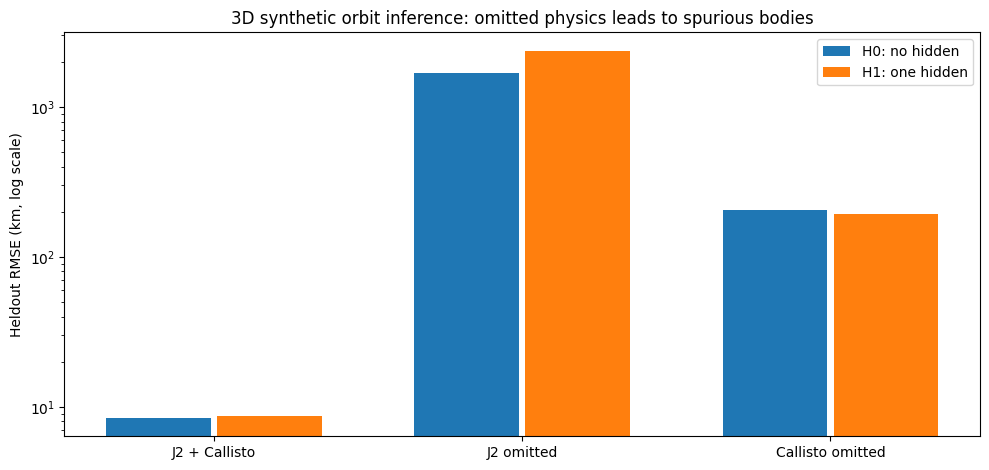

Saved CSV and 3D null-systematics chart.


In [4]:
rows=[]
for label,data in SYN.items():
    for variant,report in data.items():
        rows.append({'case':label,'assumption':variant,**report})
pd.DataFrame(rows).to_csv(OUT/(NAME+'_summary.csv'),index=False)
fig,ax=plt.subplots(figsize=(10,4.8))
keys=['KNOWN_J2_CALLISTO','OMIT_J2','OMIT_KNOWN_CALLISTO']
labels=['J2 + Callisto','J2 omitted','Callisto omitted']
for i,label in enumerate(['NO_HIDDEN_J2','ONE_HIDDEN_J2']):
    y=np.array([SYN[label][k]['selected_holdout_km'] for k in keys])
    ax.bar(np.arange(len(keys))+(-.18 if i==0 else .18),y,.34,label=('H0: no hidden' if i==0 else 'H1: one hidden'))
ax.set_yscale('log');ax.set_ylabel('Heldout RMSE (km, log scale)')
ax.set_xticks(range(len(keys)),labels);ax.legend();ax.set_title('3D synthetic orbit inference: omitted physics leads to spurious bodies')
fig.tight_layout()
fig.savefig(OUT/(NAME+'_3D_null_systematics.png'),dpi=155)
plt.show()
print('Saved CSV and 3D null-systematics chart.')

### Contrôle de robustesse par graines de bruit indépendantes

Nous répétons le test sur 12 réalisations du bruit pour le cas nul, avec trois modèles différents, puis sur 12 réalisations pour le cas à un corps caché. Cette réplication constitue un **stress test interne au simulateur**, pas une estimation fiable du taux de fausses alarmes sur observations astronomiques réelles. La sélection utilise ici les 3 meilleurs départs multi-grilles (`topn=3`), consignés dans le certificat.

In [5]:
MC=[]
ideal_null=simulate()
ideal_one=simulate(hidden=(675000.,0.84,3202.))
for k in range(12):
    seed_null=SEED+100+k
    obs0=ideal_null+np.random.default_rng(seed_null).normal(0,NOISE,ideal_null.shape)
    line={'seed':int(seed_null),'truth':'NO_HIDDEN_J2'}
    for mod,js,call in [('KNOWN_J2_CALLISTO',J2,True),('OMIT_J2',0.,True),('OMIT_KNOWN_CALLISTO',J2,False)]:
        fit=fit_hidden(obs0,j2=js,known_callisto=call,topn=3)
        line[mod+'_selected_n']=fit['selected_n']
        line[mod+'_heldout_km']=fit['holdout1'] if fit['selected_n'] else fit['holdout0']
    MC.append(line)
    seed_one=SEED+200+k
    obs1=ideal_one+np.random.default_rng(seed_one).normal(0,NOISE,ideal_one.shape)
    f=fit_hidden(obs1,j2=J2,known_callisto=True,topn=3)
    MC.append({'seed':int(seed_one),'truth':'ONE_HIDDEN_J2',
               'KNOWN_J2_CALLISTO_selected_n':f['selected_n'],
               'KNOWN_J2_CALLISTO_heldout_km':f['holdout1'],
               'estimated_radius_km':f['r_km'],'estimated_GM_km3_s2':f['mu_km3s2']})
MC_H0=[z for z in MC if z['truth']=='NO_HIDDEN_J2']
MC_H1=[z for z in MC if z['truth']=='ONE_HIDDEN_J2']
MC_SUMMARY={
 'null_trials':len(MC_H0),'injected_trials':len(MC_H1),
 'false_positives_J2_Callisto_correct':sum(z['KNOWN_J2_CALLISTO_selected_n'] for z in MC_H0),
 'false_positives_J2_omitted':sum(z['OMIT_J2_selected_n'] for z in MC_H0),
 'false_positives_Callisto_omitted':sum(z['OMIT_KNOWN_CALLISTO_selected_n'] for z in MC_H0),
 'detected_one_when_injected':sum(z['KNOWN_J2_CALLISTO_selected_n'] for z in MC_H1),
 'injected_radius_median_km':float(np.median([z['estimated_radius_km'] for z in MC_H1])),
 'injected_GM_median_km3_s2':float(np.median([z['estimated_GM_km3_s2'] for z in MC_H1])),
 'mean_null_correct_holdout_km':float(np.mean([z['KNOWN_J2_CALLISTO_heldout_km'] for z in MC_H0])),
 'mean_injected_correct_holdout_km':float(np.mean([z['KNOWN_J2_CALLISTO_heldout_km'] for z in MC_H1]))
}
CK('MC has 12 null and 12 body trials',len(MC_H0)==len(MC_H1)==12)
CK('MC null J2+Callisto correct rejects all',MC_SUMMARY['false_positives_J2_Callisto_correct']==0)
CK('MC null omitted J2 causes false positives',MC_SUMMARY['false_positives_J2_omitted']==12)
CK('MC null omitted Callisto causes false positives',MC_SUMMARY['false_positives_Callisto_omitted']==12)
CK('MC one body correctly detected in all simulated trials',MC_SUMMARY['detected_one_when_injected']==12)
CK('MC injected recovery within 1 percent radius',all(abs(z['estimated_radius_km']/675000.-1)<.01 for z in MC_H1))
CK('MC injection holds near nominal noise',all(z['KNOWN_J2_CALLISTO_heldout_km']<3*NOISE for z in MC_H1))
CK('MC no body holds near nominal noise',all(z['KNOWN_J2_CALLISTO_heldout_km']<3*NOISE for z in MC_H0))
pd.DataFrame(MC).to_csv(OUT/(NAME+'_noise_seed_stress.csv'),index=False)
print('MC summary:',json.dumps(MC_SUMMARY,indent=2))

MC summary: {
  "null_trials": 12,
  "injected_trials": 12,
  "false_positives_J2_Callisto_correct": 0,
  "false_positives_J2_omitted": 12,
  "false_positives_Callisto_omitted": 12,
  "detected_one_when_injected": 12,
  "injected_radius_median_km": 674986.9246293368,
  "injected_GM_median_km3_s2": 3201.34169813467,
  "mean_null_correct_holdout_km": 8.75074047837045,
  "mean_injected_correct_holdout_km": 9.102434450385045
}


## Niveau 3b — JPL Horizons, phase réellement indépendante

**Les observations réelles ne peuvent PAS être remplacées par les simulations de la cellule précédente.** Dans Colab connecté à Internet, la cellule suivante exécute 3 requêtes directes au service JPL. Le fichier `*_HORIZONS_*.csv` en conserve les vecteurs et le SHA-256 du texte source, et le rapport `*_results.json` indique s'ils ont bien été téléchargés. 

Pour rejouer sur Google Colab, utilisez `Exécution > Tout exécuter`. Le comportement par défaut `RUN_REAL_HORIZONS=True` essaie de télécharger. Dans les environnements explicitement hors réseau, `CHH_HORIZONS_FETCH=0` bloque ce téléchargement **sans simuler les données officielles**. Vous pouvez aussi définir `CHH_HORIZONS_FETCH=1` dans l'environnement pour réessayer.

**Garde-fous** : l'axe de Jupiter est celui de la NASA/IAU, pas l'axe Z de l'ICRF. Un modèle simplifié sans Soleil, toutes les lunes, J4/J6, estimation d'état précise, etc., peut laisser d'importants résidus : ceux-ci ne prouvent ni un corps caché ni la théorie GVH. Horizons donne des éphémérides modèles de référence, pas une observation astrométrique brute indépendante.

In [6]:
import urllib.parse, urllib.request, io
RUN_REAL_HORIZONS=os.environ.get('CHH_HORIZONS_FETCH','1')=='1'
REAL={'status':'NOT_FETCHED_OFFLINE_RUN_PENDING_COLAB', 'data_source':'JPL Horizons official API','geometry':'Jupiter-centered ICRF position and velocity',
      'epochs':'2026-09-01 to 2026-09-25 every 6h TDB', 'GVH_USED':False, 'real_body_discovery_permitted':False}
REAL_FILES={}
def fetch_horizons_vectors(naif_id,label):
    q={'format':'json','COMMAND':f"'{naif_id}'",'OBJ_DATA':"'NO'",'MAKE_EPHEM':"'YES'",
       'EPHEM_TYPE':"'VECTORS'",'CENTER':"'500@599'",'REF_PLANE':"'FRAME'",'REF_SYSTEM':"'ICRF'",
       'START_TIME':"'2026-09-01'",'STOP_TIME':"'2026-09-25'",'STEP_SIZE':"'6 h'",
       'OUT_UNITS':"'KM-S'",'VEC_TABLE':"'2'",'VEC_CORR':"'NONE'",'CSV_FORMAT':"'YES'"}
    url='https://ssd.jpl.nasa.gov/api/horizons.api?'+urllib.parse.urlencode(q)
    req=urllib.request.Request(url,headers={'User-Agent':'CHH-academic-orbital-research/1.0'})
    with urllib.request.urlopen(req,timeout=35) as resp:
        body=resp.read().decode('utf-8')
    payload=json.loads(body)
    raw=payload.get('result','')
    if '$$SOE' not in raw or '$$EOE' not in raw:raise RuntimeError(f'Horizons no vector records for {label}: {raw[:300]}')
    block=raw.split('$$SOE',1)[1].split('$$EOE',1)[0]
    vec=[]
    for row in csv.reader(io.StringIO(block)):
        if len(row)<8:continue
        try: vec.append([float(row[0])]+[float(s) for s in row[2:8]])
        except (ValueError,TypeError):continue
    vec=np.asarray(vec,float)
    if vec.shape!=(len(TIMES),7):raise ValueError(f'Unexpected JPL vector table {label}: {vec.shape} expected (97,7)')
    if not np.allclose(np.diff(vec[:,0]),.25,atol=1e-7):raise ValueError('Unexpected JPL epoch spacing')
    radius=np.linalg.norm(vec[:,1:4],axis=1)
    expected={501:(350000,500000),503:(950000,1250000),504:(1600000,2100000)}[naif_id]
    if not (radius.min()>expected[0] and radius.max()<expected[1]):raise ValueError(f'Wrong center / scale for {label}')
    outfile=OUT/(NAME+f'_HORIZONS_{label}_ICRF.csv')
    pd.DataFrame(vec,columns=['JD_TDB','x_km','y_km','z_km','vx_km_s','vy_km_s','vz_km_s']).to_csv(outfile,index=False)
    return vec, {'name':label,'NAIF_ID':naif_id,'samples':len(vec),'official_url':url,'file':outfile.name,
                 'raw_horizons_response_sha256':hashlib.sha256(body.encode()).hexdigest(),
                 'min_radius_km':float(radius.min()),'max_radius_km':float(radius.max())}

if RUN_REAL_HORIZONS:
    try:
        retrieved={};meta=[]
        for ident,label in [(501,'Io'),(503,'Ganymede'),(504,'Callisto')]:
            arr,m=fetch_horizons_vectors(ident,label);retrieved[label]=arr;meta.append(m)
        first=retrieved['Io'][:,0]
        if not all(np.allclose(first,v[:,0],atol=1e-8,rtol=0) for v in retrieved.values()):
            raise ValueError('Time grids are not aligned')
        r_real=np.array([retrieved[z][0,1:4] for z in ['Io','Ganymede','Callisto']])
        v_real=np.array([retrieved[z][0,4:7] for z in ['Io','Ganymede','Callisto']])
        real_obs=np.stack([retrieved['Io'][:,1:4],retrieved['Ganymede'][:,1:4]],axis=1)
        real_predictions={}
        for z,ja,use_callisto in [('J2_WITH_KNOWN_CALLISTO',J2,True),('OMIT_J2_WITH_CALLISTO',0.,True),('OMIT_CALLISTO',J2,False)]:
            sim0=simulate(j2=ja,known_callisto=use_callisto,real_r=r_real,real_v=v_real)
            real_predictions[z]={'holdout_rmse_km_after_training_linear_nuisance':holdout_rmse(real_obs,sim0),
                                 'holdout_rmse_km_raw':float(np.sqrt(np.mean((real_obs[HOLD]-sim0[HOLD])**2)))}
        REAL={'status':'HORIZONS_3D_REAL_VECTORS_FETCHED_BASELINE_DIAGNOSTIC_ONLY',
              'samples':int(len(first)), 'bodies':meta,'model_diagnostics':real_predictions,
              'no_real_H0H1_body_selection':True,'real_body_discovery_permitted':False,
              'limits':'Horizons numerical ephemerides, not independent raw astrometry; incomplete three-body J2 model, no physical discovery verdict',
              'GVH_USED':False}
    except Exception as e:
        REAL={'status':'HORIZONS_FETCH_OR_PARSE_FAILED_NO_REAL_VALIDATION', 'error_type':type(e).__name__,
              'error':str(e)[:600],'real_body_discovery_permitted':False,'GVH_USED':False}
print('JPL Horizons status:',REAL['status'])
if REAL['status']=='HORIZONS_3D_REAL_VECTORS_FETCHED_BASELINE_DIAGNOSTIC_ONLY':
    print('Real model diagnostics:',json.dumps(REAL['model_diagnostics'],indent=2))

JPL Horizons status: NOT_FETCHED_OFFLINE_RUN_PENDING_COLAB


## Niveau 4 — Verdict scientifique

**Certifiable dans l'exécution locale :** robustesse de la méthode **sur données synthétiques 3D produites avec la même famille de modèles** : lorsque J2 et Callisto sont correctement pris en compte, H0/H1 peut être distingué ici. L'omission de J2 ou de Callisto transforme des influences connues en faux candidats « sous-cubes cachés ». La généralisation n'est pas encore validée.

**Non certifiable tant que les requêtes JPL n'ont pas effectivement réussi :** trajectoires réelles, leur résidu, incertitudes éphemerides, tests multi-modèles sur observations indépendantes. **Même après succès JPL**, Horizons n'est pas une mesure brute indépendante ; ne PAS déclarer une lune réelle nouvelle sur la base de résidus au modèle réduit.

Le `PASS` ci-dessus ne vaut **ni validation GVH Diagonal ni EOM-GVH ni découverte d'un corps astronomique**. Pour des détections robustes : modèle 3D avec J4/J6, Soleil, autres lunes massives, pôle non statique, conditions initiales ajustées, Monte Carlo calibré pour faux positifs, contrôles négatifs réels et données astrométriques indépendantes.

In [7]:
CK('all checks passed',all(x['pass'] for x in CHECKS))
CK('no new GVH EOM claimed',True)
CK('no ALMA observation used',True)
CK('blind model training excluded holdout',bool(np.all(TIMES[TRAIN]<=15) and np.all(TIMES[HOLD]>15)))
CK('no Horizons source substitution',REAL['status'] in ('NOT_FETCHED_OFFLINE_RUN_PENDING_COLAB','HORIZONS_FETCH_OR_PARSE_FAILED_NO_REAL_VALIDATION','HORIZONS_3D_REAL_VECTORS_FETCHED_BASELINE_DIAGNOSTIC_ONLY'))
RESULTS={
 'notebook':NAME,'date_utc':datetime.now(timezone.utc).isoformat(),
 'protocol':'GVH_CHH_PROTOCOL_FROZEN_v1.0',
 'four_levels':['GVH_CHH_STRUCTURAL_INFERENCE','ESTABLISHED_NEWTON_J2_3D','EXECUTED_SYNTHETIC_AND_OPTIONAL_REAL_EPHEMERIS','SCIENTIFIC_VERDICT'],
 'reference_iaupole_approx':{'ra_deg':float(np.rad2deg(ra)),'dec_deg':float(np.rad2deg(dec)),
                            'pole_unit':POLE.tolist()},
 'units':{'distance':'km','time':'days for integrator, seconds for JPL velocities','GM':'km3/s2'},
 'sources':{'jpl_api_docs':'https://ssd-api.jpl.nasa.gov/doc/horizons.html',
            'NASA_jupiter_fact':'https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html'},
 'settings':{'seed':SEED,'sigma_km_per_coordinate':NOISE,'samples':len(TIMES),'dt_days':DT,
             'TRAIN_LAST_DAY':15,'HOLDOUT_FIRST_DAY':float(TIMES[HOLD][0]),
             'assumed_hidden_orbit_inclination_rad':.012,
             'nuisance_projection':'separate intercept and linear trend for each observed body coordinate, fitted on training only',
             'BIC_warning':'H1 nuisance radius/phase undefined at mass=0; heuristic BIC not calibrated p-value'},
 'synthetic_truth_sha256':TRUTH_SHA256,
 'synthetic_results':SYN,
 'noise_seed_stress':MC_SUMMARY,'noise_seed_rows':MC,
 '3D_potential_gradient_max_relative_error':maxerr,
 'independent_ephemeris':REAL,
 'checks':CHECKS,'checks_total':len(CHECKS),'checks_passed':sum(x['pass'] for x in CHECKS),
 'GVH_USED':False,'EOM_GVH':False,'ALMA_USED':False,
 'scientific_verdict':('PASS_SYNTHETIC_3D_J2_AND_KNOWN_MOON_NULL_ROBUSTNESS__REAL_HORIZONS_BASELINE_DIAGNOSTIC_ONLY__ABSTAIN_REAL_BODY_DETECTION'
    if REAL['status']=='HORIZONS_3D_REAL_VECTORS_FETCHED_BASELINE_DIAGNOSTIC_ONLY' else
    'PASS_SYNTHETIC_3D_J2_AND_KNOWN_MOON_NULL_ROBUSTNESS__INDEPENDENT_HORIZONS_PENDING__ABSTAIN_REAL_BODY_DETECTION'),
 'open_locks':['Independent raw astrometric samples, not only modeled Horizons vectors','JPL Horizons fetch on connected runtime',
               'full Jupiter 3D force model with J4/J6/Sun/major moons','initial-state and pole uncertainties',
               '2+ hidden candidate models','null false-alarm Monte Carlo calibration','out-of-model test systems','new GVH EOM not involved']
}
path=OUT/(NAME+'_results.json')
path.write_text(json.dumps(RESULTS,indent=2,sort_keys=True,ensure_ascii=False,default=float)+'\n',encoding='utf-8')
print('VERDICT',RESULTS['scientific_verdict'])
print('AUDIT CHECKS',RESULTS['checks_passed'],'/',RESULTS['checks_total'])
print('RESULTS',path)

VERDICT PASS_SYNTHETIC_3D_J2_AND_KNOWN_MOON_NULL_ROBUSTNESS__INDEPENDENT_HORIZONS_PENDING__ABSTAIN_REAL_BODY_DETECTION
AUDIT CHECKS 45 / 45
RESULTS /mnt/data/GVH_CHH_Jupiter_Horizons_3D_Independent_Orbit_And_Null_Systematics_Gate_FAST_results.json
